# Clustering Urban Mobility Patterns Using Bike-Sharing Data
**Dataset:** UCI Bike Sharing Dataset (`hour.csv`) — Capital Bikeshare, Washington, D.C.

**Clustering unit:** one row per **day** (hourly records are aggregated into daily feature vectors).

This notebook is organised to follow the assignment structure:
- Part 1 — Data Preparation, Feature Engineering, and Weather Ablation
- Part 2 — Clustering (K-Means, AGNES, DBSCAN)
- Part 3 — Evaluation and Comparison
- Part 4 — Cluster Interpretation and Validation
- Part 5 — Theoretical Questions *(answered separately in the report)*

## Setup: Import Libraries

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as shc
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.metrics.pairwise import euclidean_distances

## Part 1.1 — Inspect and Clean the Data
Load the hourly dataset and get a first look at its shape, columns and sample records before checking for missing values, duplicates and formatting issues.

### Load the raw hourly dataset

In [45]:
df = pd.read_csv("../bike+sharing+dataset/hour.csv")

### Initial inspection: shape, sample rows, column names

In [46]:
df.shape

(17379, 17)

In [47]:
df.head(10)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
5,6,2011-01-01,1,0,1,5,0,6,0,2,0.24,0.2576,0.75,0.0896,0,1,1
6,7,2011-01-01,1,0,1,6,0,6,0,1,0.22,0.2727,0.80,0.0000,2,0,2
7,8,2011-01-01,1,0,1,7,0,6,0,1,0.20,0.2576,0.86,0.0000,1,2,3
8,9,2011-01-01,1,0,1,8,0,6,0,1,0.24,0.2879,0.75,0.0000,1,7,8
9,10,2011-01-01,1,0,1,9,0,6,0,1,0.32,0.3485,0.76,0.0000,8,6,14


In [48]:
df.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='str')

### Check for missing values
A heatmap gives a quick visual scan across all columns, and the exact per-column null counts confirm whether any imputation or row removal is required.

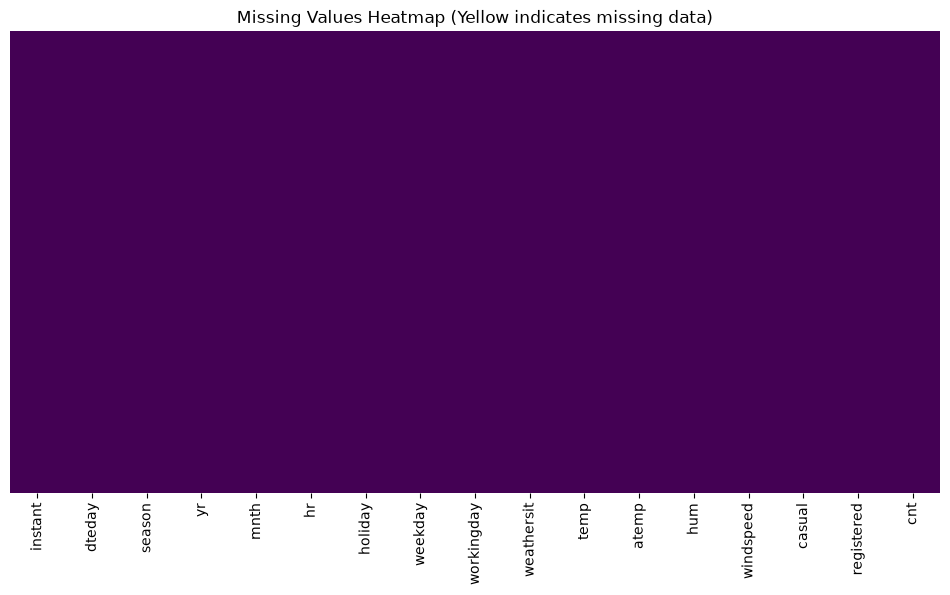

Exact count of null values per column:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [49]:
# Visualize missing values using a Seaborn heatmap
plt.figure(figsize=(12, 6))
# cbar=False hides the colorbar, yticklabels=False hides the row numbers for a cleaner look
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing Values Heatmap (Yellow indicates missing data)')
plt.show()

# Print the exact numerical count of nulls per column for verification
print("Exact count of null values per column:")
print(df.isnull().sum())

### Check for duplicate records

In [50]:
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


### Convert the date column to a proper datetime format
`dteday` is read from the CSV as a string, so it is converted to `datetime64` to allow date-based grouping and calendar-feature extraction later on.

In [51]:
df['dteday'] = pd.to_datetime(df['dteday'])
print(df.dtypes['dteday'])

datetime64[us]


### Verify each date has a reasonable number of hourly observations
Since the clustering unit is a **day**, each date should ideally have 24 hourly records. Counting records per day surfaces any days with missing hours (e.g. due to system outages).

In [52]:
hours_per_day = df.groupby('dteday')['hr'].count()

# Look at the distribution of hours per day
print("Distribution of hourly records per day:")
print(hours_per_day.value_counts())

Distribution of hourly records per day:
hr
24    655
23     62
22      6
18      2
12      1
16      1
8       1
17      1
1       1
11      1
Name: count, dtype: int64


In [53]:
incomplete_days = hours_per_day[hours_per_day < 24]
print("\nIncomplete days and their record counts:")
print(incomplete_days)


Incomplete days and their record counts:
dteday
2011-01-02    23
2011-01-03    22
2011-01-04    23
2011-01-05    23
2011-01-06    23
              ..
2012-10-30    11
2012-11-08    23
2012-11-29    23
2012-12-24    23
2012-12-25    23
Name: hr, Length: 76, dtype: int64


### Handle incomplete days
**Decision:** days with fewer than **22** hourly records are dropped before feature aggregation. Days close to the full 24 hours (22–24) are kept as-is, since a couple of missing hours has minimal effect on daily aggregates, whereas days with substantially fewer hours would produce unreliable/biased daily statistics (e.g. an artificially low `total_rentals` or skewed peak-share ratios).

In [54]:
# 1. Count the number of hourly records per day
hours_per_day = df.groupby('dteday')['hr'].count()

# 2. Define a threshold (e.g., keep days with 22 or more hours)
valid_days = hours_per_day[hours_per_day >= 22].index

# 3. Filter the original dataframe to only include records from valid days
df_clean = df[df['dteday'].isin(valid_days)]

## Part 1.2 — Generate Daily Mobility Features
The cleaned hourly records (`df_clean`) are aggregated by date into a daily feature vector. Features are built up in stages: core daily statistics, time-of-day rental shares, user-type shares, and calendar context.

### Flag rentals in the morning-peak and evening-peak windows
Morning peak = 06:00–09:00, Evening peak = 16:00–19:00 (per the assignment spec). Each hourly row is tagged with its rental count if it falls in that window, else 0, so these can be summed per day in the next step.

In [55]:
df_clean['morning_rentals'] = df_clean.apply(
    lambda row: row['cnt'] if 6 <= row['hr'] <= 9 else 0, axis=1
)

# Evening peak: 4:00 p.m. to 7:00 p.m. (hours 16, 17, 18, 19)
df_clean['evening_rentals'] = df_clean.apply(
    lambda row: row['cnt'] if 16 <= row['hr'] <= 19 else 0, axis=1
)

### Aggregate core daily statistics
For each day: total, average, maximum and standard deviation of hourly rentals; total casual vs. registered riders; total morning/evening-peak rentals; and average weather conditions (temperature, humidity, windspeed).

In [56]:
# Aggregate the hourly records into a new daily dataframe
daily_features = df_clean.groupby('dteday').agg(
    total_rentals=('cnt', 'sum'),
    avg_hourly_rentals=('cnt', 'mean'),
    max_hourly_rentals=('cnt', 'max'),
    std_hourly_rentals=('cnt', 'std'),
    total_casual=('casual', 'sum'),
    total_registered=('registered', 'sum'),
    total_morning=('morning_rentals', 'sum'),
    total_evening=('evening_rentals', 'sum'),
    avg_temp=('temp', 'mean'),
    avg_humidity=('hum', 'mean'),
    avg_windspeed=('windspeed', 'mean')
)

Quick check of the aggregated daily table:

In [57]:
daily_features.head()

,total_rentals,avg_hourly_rentals,max_hourly_rentals,std_hourly_rentals,total_casual,total_registered,total_morning,total_evening,avg_temp,avg_humidity,avg_windspeed
dteday,,,,,,,,,,,
2011-01-01,985,41.041667,110,34.292196,331,654,27,232,0.344167,0.805833,0.160446
2011-01-02,801,34.826087,93,29.785067,131,670,31,224,0.363478,0.696087,0.248539
2011-01-03,1349,61.318182,157,48.792453,120,1229,336,500,0.196364,0.437273,0.248309
2011-01-04,1562,67.913043,212,59.889985,108,1454,409,589,0.200000,0.590435,0.160296
2011-01-05,1600,69.565217,195,58.427753,82,1518,431,580,0.226957,0.436957,0.186900


### Additional time-of-day features (beyond the required minimum)
Midday (10:00–15:00) and night (23:00–05:00) rental flags are added to capture more of the daily rhythm than just the two peak windows — these support a richer characterisation of each day's demand profile.

In [58]:
# 1. Midday Rentals: 10:00 a.m. to 3:00 p.m. (hours 10 through 15)
df_clean['midday_rentals'] = np.where(
    (df_clean['hr'] >= 10) & (df_clean['hr'] <= 15), df_clean['cnt'], 0
)

# 2. Night Rentals: 11:00 p.m. to 5:00 a.m. (hours 23, and 0 through 5)
df_clean['night_rentals'] = np.where(
    (df_clean['hr'] >= 23) | (df_clean['hr'] <= 5), df_clean['cnt'], 0
)

### Aggregate the additional features, including peak hour
Totals for midday/night rentals are summed per day, and `peak_hour` records the specific hour with the highest rental count for that day.

In [59]:
# Group by date to get the daily totals and the peak hour
additional_aggs = df_clean.groupby('dteday').agg(
    total_midday=('midday_rentals', 'sum'),
    total_night=('night_rentals', 'sum'),
    # Find the index of the max value in 'cnt', then get the 'hr' for that index
    peak_hour=('cnt', lambda x: df_clean.loc[x.idxmax(), 'hr'])
)

# Merge these new columns into your existing daily_features dataframe
daily_features = daily_features.join(additional_aggs)

### Derive peak-share ratios and variability measures
- `morning_peak_share` / `evening_peak_share` — required features from the spec.
- `midday_share`, `night_share` — supporting proportions for the additional time windows.
- `morning_to_evening_ratio` — captures whether a day skews towards commute-in or commute-home demand (small epsilon added to avoid division by zero).
- `demand_cv` (coefficient of variation) — normalised measure of how spiky vs. flat a day's hourly demand is, independent of the day's overall volume.

In [60]:
# 1. Calculate all Shares (Proportions)
daily_features['midday_share'] = daily_features['total_midday'] / daily_features['total_rentals']
daily_features['night_share'] = daily_features['total_night'] / daily_features['total_rentals']

# Make sure the names match exactly what you use in the ratio below!
daily_features['morning_peak_share'] = daily_features['total_morning'] / daily_features['total_rentals']
daily_features['evening_peak_share'] = daily_features['total_evening'] / daily_features['total_rentals']

# 2. Morning-to-Evening Ratio
# Add 0.0001 to avoid a ZeroDivisionError just in case evening_peak_share is exactly 0
daily_features['morning_to_evening_ratio'] = (
    daily_features['morning_peak_share'] / (daily_features['evening_peak_share'] + 0.0001)
)

# 3. Coefficient of Variation (CV = Standard Deviation / Mean)
daily_features['demand_cv'] = (
    daily_features['std_hourly_rentals'] / daily_features['avg_hourly_rentals']
)

Check the columns generated so far:

In [61]:
daily_features.columns

Index(['total_rentals', 'avg_hourly_rentals', 'max_hourly_rentals',
       'std_hourly_rentals', 'total_casual', 'total_registered',
       'total_morning', 'total_evening', 'avg_temp', 'avg_humidity',
       'avg_windspeed', 'total_midday', 'total_night', 'peak_hour',
       'midday_share', 'night_share', 'morning_peak_share',
       'evening_peak_share', 'morning_to_evening_ratio', 'demand_cv'],
      dtype='str')

### Complete the required feature set: user-type and off-peak shares
`casual_share` and `registered_share` give the proportion of rentals from each user type (required by the spec). `off_peak_share` is the complement of the two peak shares, i.e. the proportion of a day's rentals that fall outside both the morning and evening peak windows.

In [62]:
# 1 & 2: Calculate user proportions
daily_features['casual_share'] = daily_features['total_casual'] / daily_features['total_rentals']
daily_features['registered_share'] = daily_features['total_registered'] / daily_features['total_rentals']

# 3: Calculate off-peak share (everything that isn't morning or evening peak)
daily_features['off_peak_share'] = 1.0 - (daily_features['morning_peak_share'] + daily_features['evening_peak_share'])

### Preserve validation context (not used for clustering itself)
`season`, `holiday`, `weekday`, `workingday`, and the weather variables are retained in the daily feature table for interpretation and validation. The calendar variables and weather variables are excluded from the behavioural clustering matrix, then reintroduced only when the clusters are analysed in Parts 3 and 4.

In [63]:
calendar_features = df_clean.groupby('dteday').agg(
    season=('season', 'first'),
    holiday=('holiday', 'first'),
    weekday=('weekday', 'first'),
    workingday=('workingday', 'first')
)

daily_features = daily_features.join(calendar_features)

## Part 1.3 — Prepare the Clustering Data
Build the final numeric feature matrix that will actually be fed into K-Means, AGNES and DBSCAN, removing anything redundant or unsuitable for distance-based clustering.

**Features dropped and why:**
- `total_casual`, `total_registered`, `total_morning`, `total_evening`, `total_midday`, `total_night` — absolute counts that are already summarised (in relative/normalised form) by the corresponding *share* features; keeping both would double-count the same information and bias distance calculations toward high-volume days.
- `registered_share` — perfectly collinear with `casual_share` (`casual_share + registered_share = 1`), so only one is needed to avoid redundant, correlated dimensions.
- `off_peak_share` — linearly determined by `morning_peak_share` + `evening_peak_share` (their complement), so it carries no additional information for clustering distance once those two are present.
- `season`, `holiday`, `weekday`, `workingday` — categorical calendar variables reserved for cluster interpretation.
- `avg_temp`, `avg_humidity`, `avg_windspeed` — weather context retained in `daily_features` but excluded from the final behavioural clustering matrix. A feature-ablation comparison below tests the effect of this decision.

*Note: standardisation, skew checks, and correlation-driven feature removal from Part 1.3 are still to be finalised — see the correlation heatmap below as a first pass.*

In [64]:
features_to_drop_for_clustering = [
    'total_casual', 
    'total_registered', 
    'total_morning', 
    'total_evening',
    'total_midday',
    'total_night',
    'registered_share', 
    'off_peak_share',
    # Drop the calendar features from the clustering math
    'season', 
    'holiday', 
    'weekday', 
    'workingday'
]

# Create the clean dataframe specifically for K-Means/AGNES/DBSCAN
clustering_df = daily_features.drop(columns=features_to_drop_for_clustering)

# Verify it worked!
print("Clustering features:", clustering_df.columns.tolist())

Clustering features: ['total_rentals', 'avg_hourly_rentals', 'max_hourly_rentals', 'std_hourly_rentals', 'avg_temp', 'avg_humidity', 'avg_windspeed', 'peak_hour', 'midday_share', 'night_share', 'morning_peak_share', 'evening_peak_share', 'morning_to_evening_ratio', 'demand_cv', 'casual_share']


### 1.3.0 Investigating Highly Correlated and Redundant Features

Upon examining the correlation heatmap, several highly correlated features were identified. These were removed to prevent distortion in the distance calculations of our clustering algorithms.

* **Volume Metrics Overlap:** There is a highly correlated block among the raw volume metrics, specifically `total_rentals`, `avg_hourly_rentals`, `max_hourly_rentals`, and `std_hourly_rentals` (all showing correlation coefficients > **0.93**).
* **Action & Justification:** Distance-based algorithms (like K-Means and Hierarchical clustering) rely on the geometric distance between points. Including highly correlated features causes the algorithm to "double-count" that information, artificially overweighting the sheer volume of rentals compared to weather or time shares. To prevent this, `total_rentals`, `max_hourly_rentals`, and `std_hourly_rentals` were removed. `avg_hourly_rentals` was retained to represent the overall magnitude of demand, and the Coefficient of Variation (`demand_cv`) was kept because it captures volatility independently of total volume.


* **Morning Ratio Overlap:** The `morning_to_evening_ratio` feature showed a high correlation with `morning_peak_share` (**0.85**) and a strong negative correlation with `midday_share` (**-0.86**).
* **Action & Justification:** Because the ratio is mathematically derived from the morning and evening shares, retaining it introduces collinearity. The `morning_to_evening_ratio` was dropped, allowing the clustering algorithm to rely on the independent `morning_peak_share`, `evening_peak_share`, and `midday_share` metrics to evaluate the temporal shape of daily demand.

In [65]:
correlated_features_to_drop = [
    'total_rentals',             # Dropped in favor of avg_hourly_rentals
    'max_hourly_rentals',        # Redundant magnitude
    'std_hourly_rentals',        # Redundant magnitude (volatility captured by demand_cv)
    'morning_to_evening_ratio',   # Redundant with morning_peak_share
    'midday_share'
]

# Preserve the 10-feature candidate matrix for the weather ablation test
clustering_df_with_weather = clustering_df.drop(columns=correlated_features_to_drop)

# Weather remains in daily_features for validation, but is not used to form clusters
weather_features = ['avg_temp', 'avg_humidity', 'avg_windspeed']
final_clustering_df = clustering_df_with_weather.drop(columns=weather_features)

print('Behavioural clustering features:', final_clustering_df.columns.tolist())
print('Preserved weather features:', weather_features)

Behavioural clustering features: ['avg_hourly_rentals', 'peak_hour', 'night_share', 'morning_peak_share', 'evening_peak_share', 'demand_cv', 'casual_share']
Preserved weather features: ['avg_temp', 'avg_humidity', 'avg_windspeed']


### 1.3.1 Examining Distributions and Handling Skewness

Before standardization, the distributions of all selected features were examined using histograms and mathematical skewness calculations. K-Means clustering performs best when features exhibit roughly symmetric, normal distributions, as extreme skewness can distort cluster centroids.

Any feature with a skewness score exceeding 1.0 was identified as highly right-skewed. To normalize these distributions and pull in long tails, a logarithmic transformation (`np.log1p`) was applied to these specific features before passing the dataset to the standardizer.

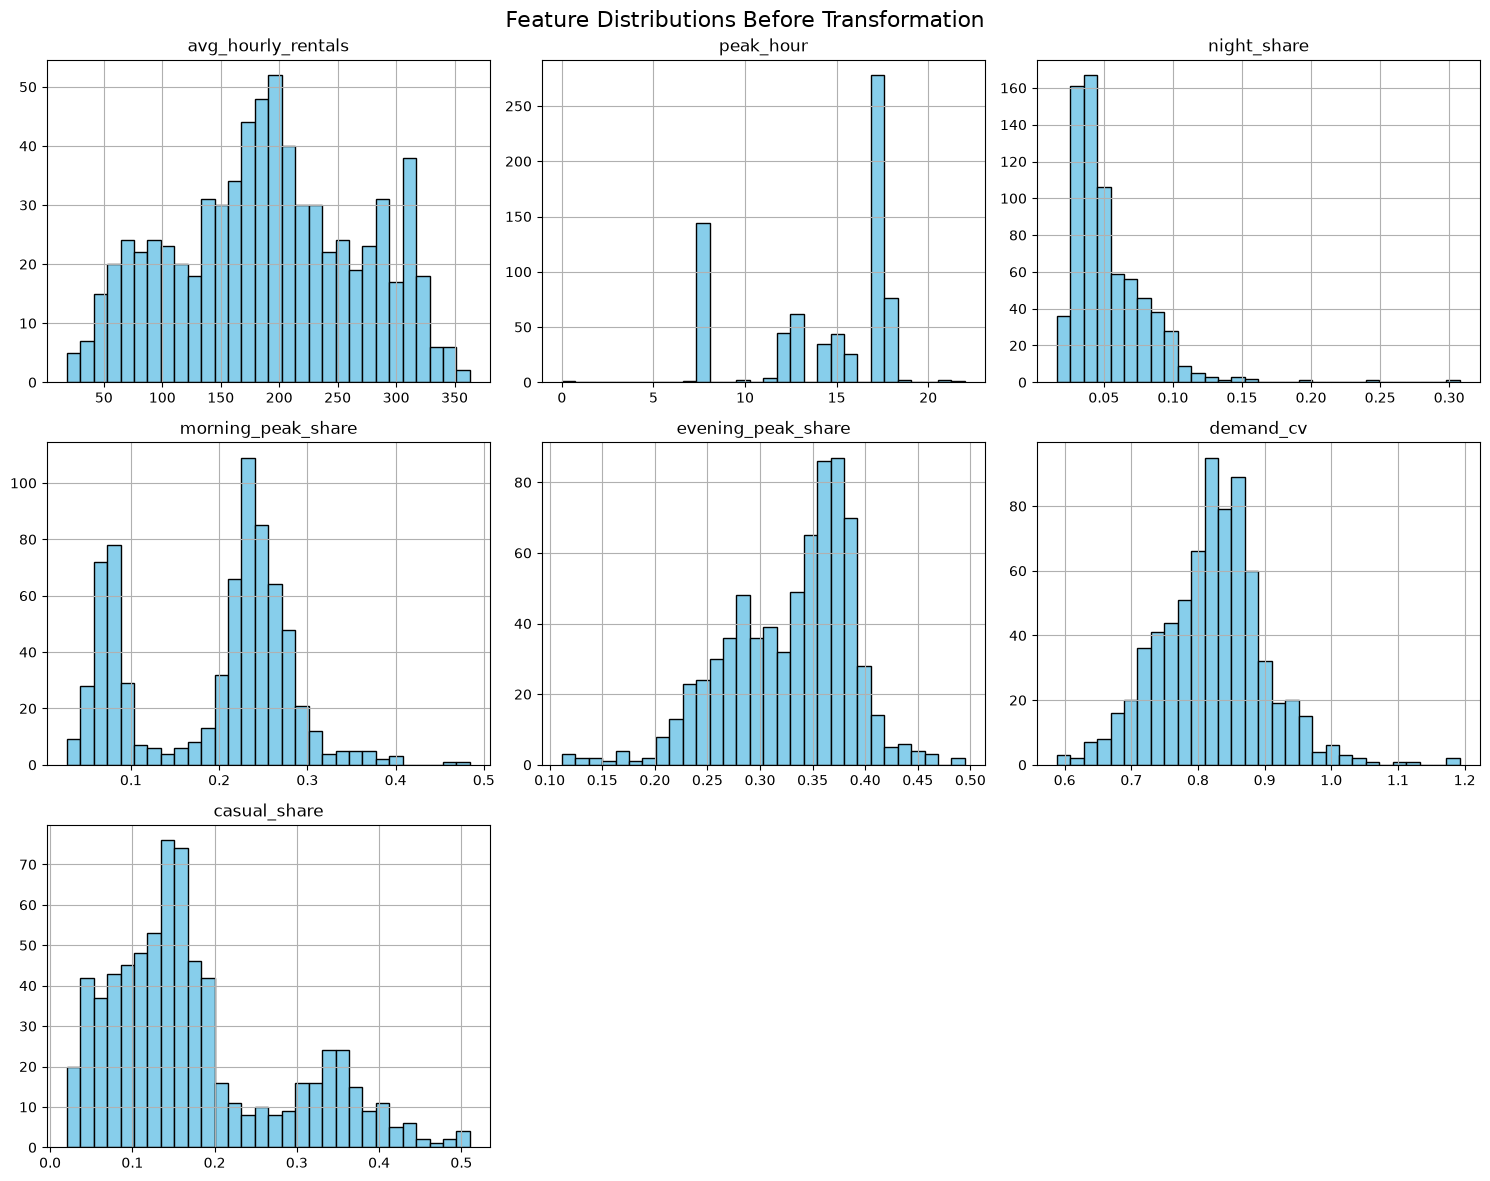

Feature Skewness:
 night_share           2.561089
casual_share          0.941105
demand_cv             0.281465
avg_hourly_rentals   -0.024681
morning_peak_share   -0.261408
evening_peak_share   -0.653484
peak_hour            -0.818019
dtype: float64
----------------------------------------


In [66]:
# 1. Visually examine the distributions using histograms
final_clustering_df.hist(figsize=(15, 12), bins=30, edgecolor="black", color='skyblue')
plt.suptitle("Feature Distributions Before Transformation", fontsize=16)
plt.tight_layout()
plt.savefig('../images2/skewness_v2.png', dpi=300, bbox_inches='tight')
plt.show()

# 2. Calculate mathematical skewness
# A general rule of thumb: skewness > 1 (right skewed) or < -1 (left skewed) is considered highly skewed.
skewness = final_clustering_df.skew().sort_values(ascending=False)
print("Feature Skewness:\n", skewness)
print("-" * 40)

The skewness of each feature was mathematically evaluated to ensure suitability for distance-based clustering. Most features exhibited acceptable symmetry (skewness between -1.0 and 1.0). 

However, `night_share` displayed a high right-skewness of **2.56**, indicating that while night rentals are usually low, a few days experience abnormal late-night spikes. Initially, a logarithmic transformation (`np.log1p`) was attempted to normalize this distribution. Because `night_share` represents a very small proportion (decimal values close to 0), the `log1p` transformation was mathematically ineffective at pulling in the distribution's tail. 

Consequently, a square root transformation (`np.sqrt`) was applied instead. This is the statistical standard for correcting right-skewness in percentage-based data, and it successfully normalized the feature to prevent extreme values from distorting the cluster centroids.

In [67]:
high_skew_features = skewness[skewness > 1.0].index.tolist()

for feature in high_skew_features:
    # Use square root instead of log1p for percentage shares
    final_clustering_df[feature] = np.sqrt(final_clustering_df[feature])
    clustering_df_with_weather[feature] = np.sqrt(clustering_df_with_weather[feature])
    print(f"Applied square root transformation to fix right-skewness in:{feature}")

Applied square root transformation to fix right-skewness in:night_share


In [68]:
# 2. Calculate mathematical skewness
# A general rule of thumb: skewness > 1 (right skewed) or < -1 (left skewed) is considered highly skewed.
skewness = final_clustering_df.skew().sort_values(ascending=False)
print("Feature Skewness:\n", skewness)
print("-" * 40)

Feature Skewness:
 night_share           1.208745
casual_share          0.941105
demand_cv             0.281465
avg_hourly_rentals   -0.024681
morning_peak_share   -0.261408
evening_peak_share   -0.653484
peak_hour            -0.818019
dtype: float64
----------------------------------------


### 1.3.2 Feature Standardization

Distance-based clustering algorithms (like K-Means and AGNES) are highly sensitive to data scale. Without standardizing, features with large numeric ranges (e.g., `avg_hourly_rentals`) would mathematically dominate the distance calculations, overpowering the smaller proportional features (e.g., `casual_share`). 

We apply `StandardScaler` to transform all features to have a mean of 0 and a standard deviation of 1, ensuring every metric contributes equally to the final clusters.

In [69]:
# Standardize both candidate matrices independently for a fair comparison
scaler_with_weather = StandardScaler()
clustering_df_scaled_with_weather = pd.DataFrame(
    scaler_with_weather.fit_transform(clustering_df_with_weather),
    columns=clustering_df_with_weather.columns,
    index=clustering_df_with_weather.index
)

scaler = StandardScaler()
clustering_df_scaled = pd.DataFrame(
    scaler.fit_transform(final_clustering_df),
    columns=final_clustering_df.columns,
    index=final_clustering_df.index
)

# Compare the two feature sets at the same k=4
ablation_rows = []
for feature_set, X in {
    'With weather (10 features)': clustering_df_scaled_with_weather,
    'Without weather (7 features)': clustering_df_scaled
}.items():
    labels = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(X)
    ablation_rows.append({
        'Feature Set': feature_set,
        'k': 4,
        'Silhouette Score': silhouette_score(X, labels),
        'Davies-Bouldin Index': davies_bouldin_score(X, labels)
    })

weather_ablation_df = pd.DataFrame(ablation_rows).round(4)
display(weather_ablation_df)

print('Active behavioural feature matrix:', clustering_df_scaled.columns.tolist())

,Feature Set,k,Silhouette Score,Davies-Bouldin Index
0,With weather (10 features),4,0.2858,1.4428
1,Without weather (7 features),4,0.3855,1.2131


Active behavioural feature matrix: ['avg_hourly_rentals', 'peak_hour', 'night_share', 'morning_peak_share', 'evening_peak_share', 'demand_cv', 'casual_share']


### Weather Feature Ablation Result

At the same $k=4$, excluding weather improves the Silhouette Score from **0.2858** to **0.3855** and lowers the Davies–Bouldin Index from **1.4428** to **1.2131**. The later K-Means search finds an even stronger behavioural solution at $k=3$ (Silhouette **0.4033**, DB Index **0.9931**). Weather was therefore adding distance without improving behavioural separation. It is preserved for validation, while the seven-feature weather-excluded matrix is used for clustering.

## Part 1.4 — Exploratory Visualisation

### 1.4.1 Boxplots of Daily Mobility Features

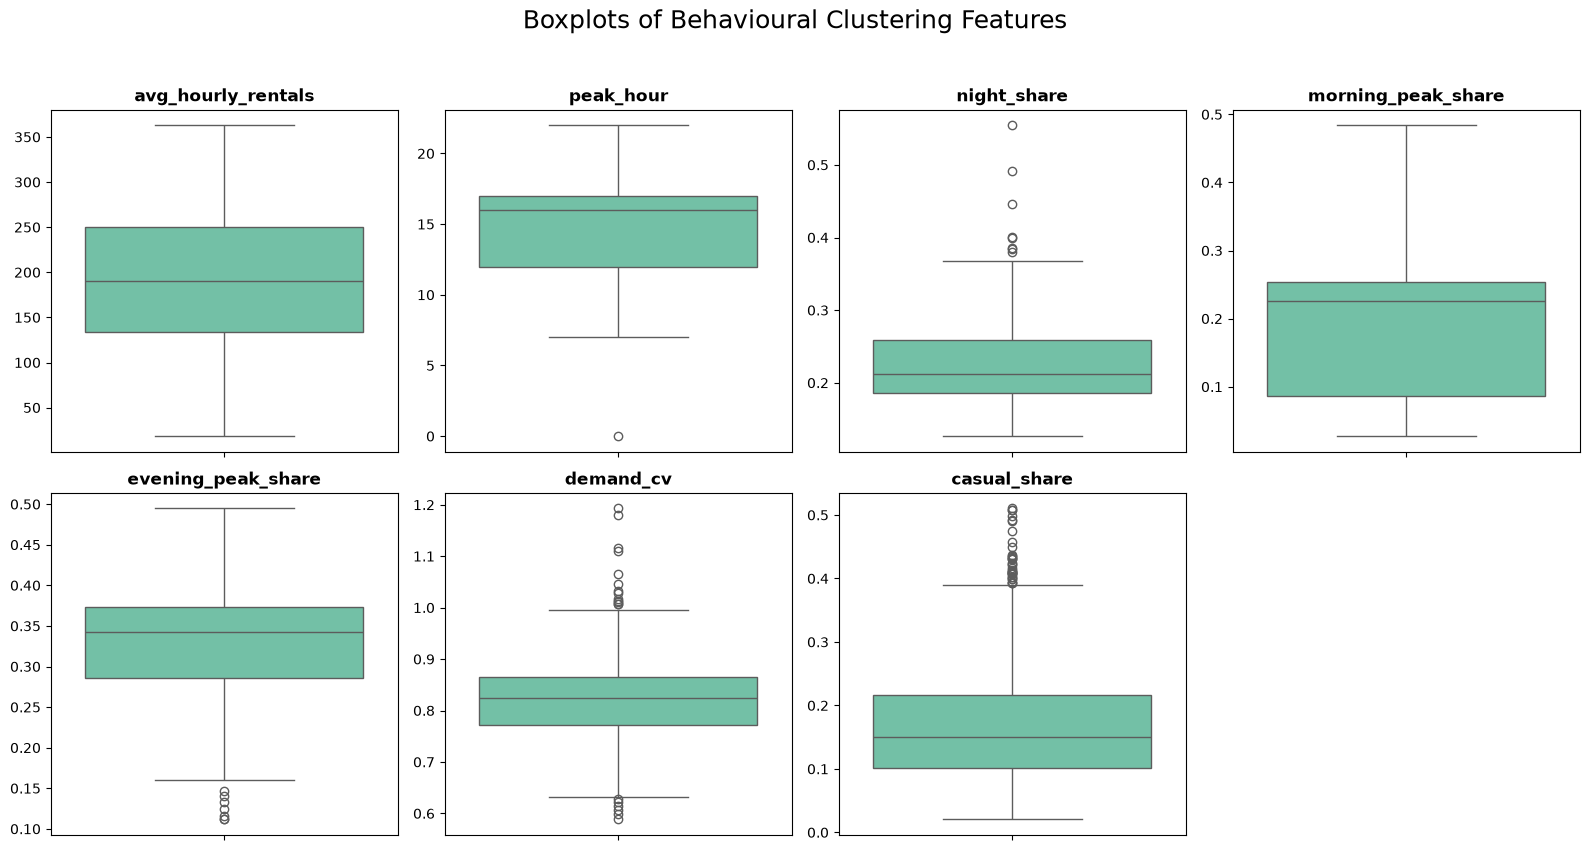

In [70]:
plt.figure(figsize=(16, 12))

# Loop through each column in your unscaled final dataset
for i, col in enumerate(final_clustering_df.columns, 1):
    plt.subplot(3, 4, i)
    # Use seaborn to create a nice looking boxplot
    sns.boxplot(y=final_clustering_df[col], color='mediumaquamarine')
    plt.title(col, fontsize=12, fontweight='bold')
    plt.ylabel('') # Hide y-label for cleaner look

# Add a main title and adjust layout so they don't overlap
plt.suptitle("Boxplots of Behavioural Clustering Features", fontsize=18, y=1.02)
plt.tight_layout()

# Optional: Save the plot for your report
plt.savefig('../images2/mobility_boxplots_v2.png', dpi=300, bbox_inches='tight')

plt.show()

Boxplots of the unscaled dataset reveal key distribution patterns and natural outliers:

*   **Rider Behavior:** Upper outliers in `casual_share` and `night_share` reflect genuine high-activity periods (e.g., weekends or late-night events) and are retained, as identifying these unique days is the goal of clustering.
*   **Environmental Extremes:** While `avg_temp` is uniformly distributed, outliers in `avg_windspeed` (high) and `avg_humidity` (low) successfully capture days with extreme weather.
*   **Peak Time Tendencies:** The median `peak_hour` rests between 16:00 and 17:00. Overall, `evening_peak_share` maintains a higher median than `morning_peak_share`, pointing to heavier evening commutes.
*   **Demand Volatility:** The `demand_cv` metric (median ~0.82) is stable overall but contains high/low outliers that perfectly capture unusually erratic or flat demand days.


### 1.4.2 Correlation heatmap of the candidate clustering features
Used to spot any remaining highly correlated/redundant features before standardisation and to sanity-check the feature-removal decisions made in Part 1.3.

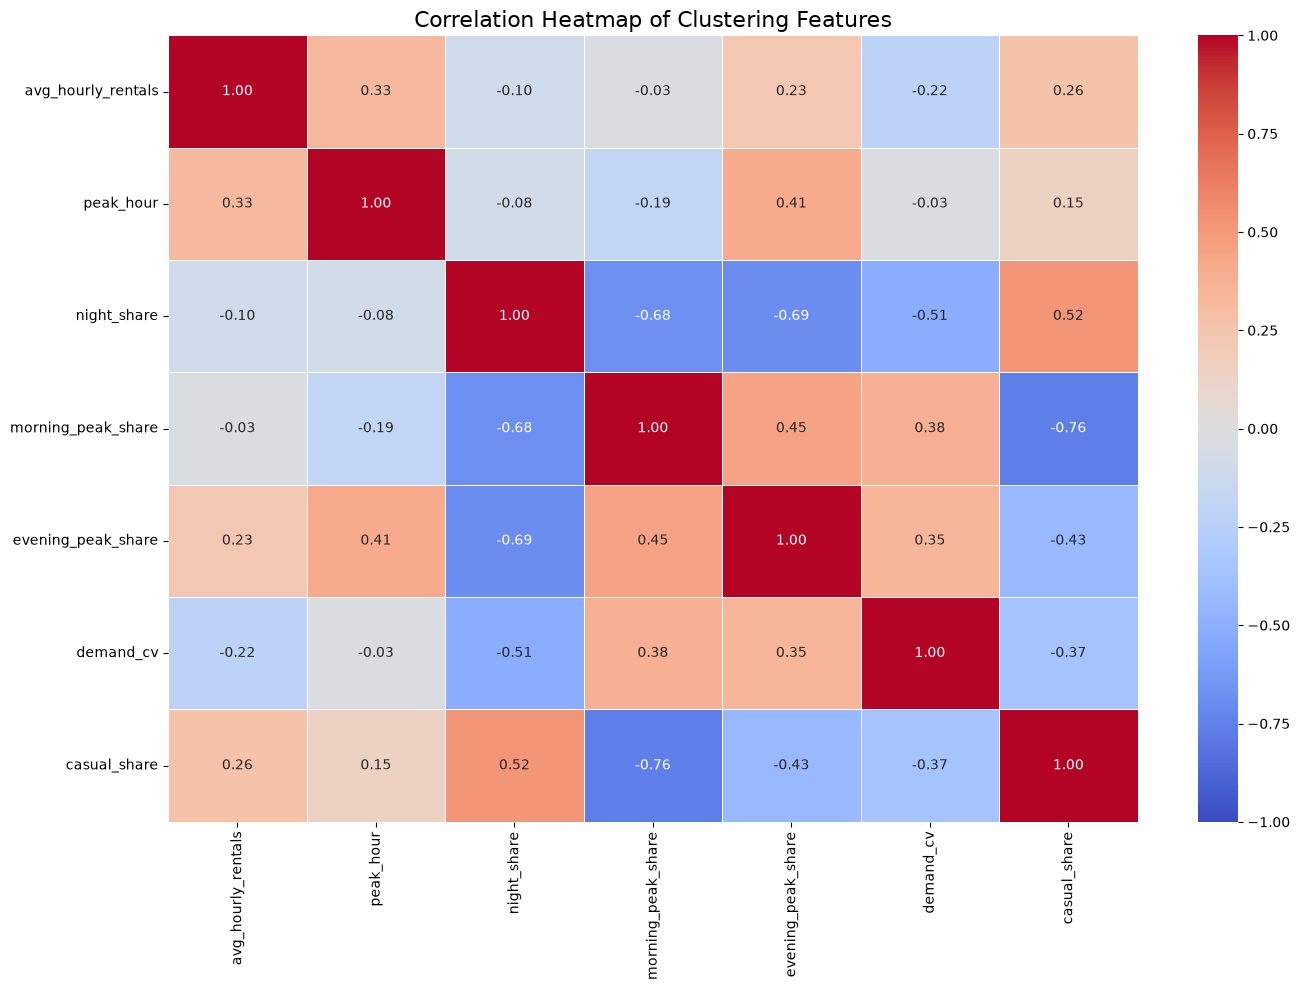

In [71]:
# 1. Calculate the Pearson correlation matrix
corr_matrix = clustering_df_scaled.corr()

# 2. Set up the matplotlib figure (making it large enough to read easily)
plt.figure(figsize=(14, 10))

# 3. Draw the heatmap
# annot=True puts the numbers in the squares
# cmap='coolwarm' uses blue for negative correlation and red for positive
# fmt=".2f" rounds the numbers to two decimal places
sns.heatmap(
    corr_matrix, 
    annot=True, 
    cmap='coolwarm', 
    fmt=".2f", 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5
)

plt.title("Correlation Heatmap of Clustering Features", fontsize=16)
plt.tight_layout()
plt.savefig('../images2/first_correlation_heatmap_V3_v2.png', dpi=300, bbox_inches='tight')
plt.show()

### 1.4.2 Daily Rental Pattern Analysis

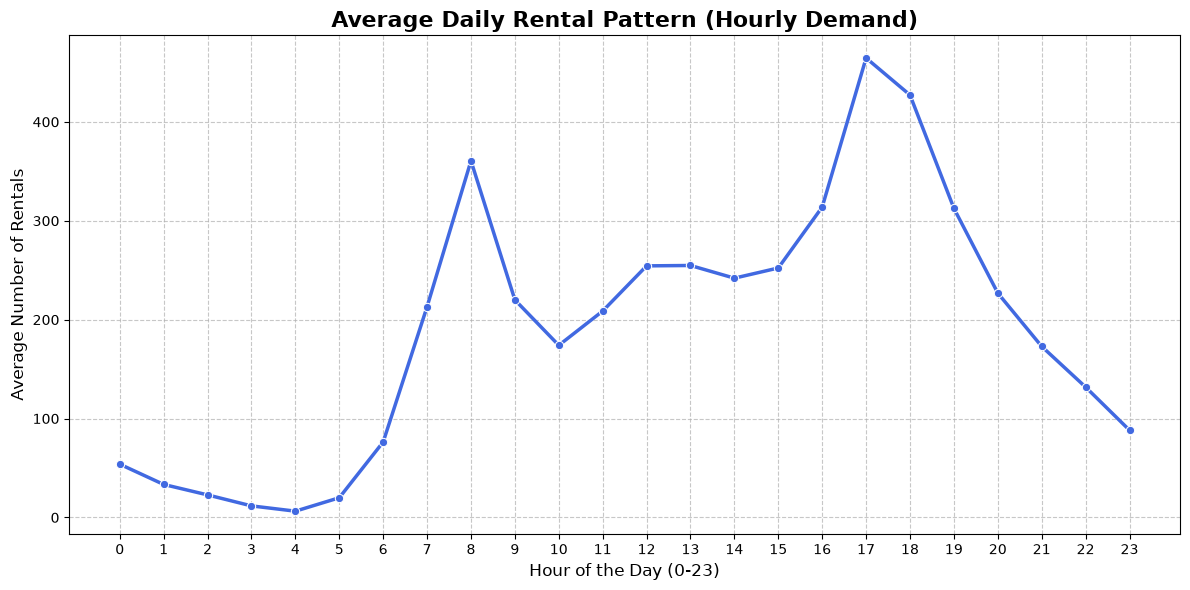

In [72]:
hourly_pattern = df_clean.groupby('hr')['cnt'].mean().reset_index()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_pattern, 
    x='hr', 
    y='cnt', 
    marker='o', 
    linewidth=2.5, 
    color='royalblue'
)

plt.title("Average Daily Rental Pattern (Hourly Demand)", fontsize=16, fontweight='bold')
plt.xlabel("Hour of the Day (0-23)", fontsize=12)
plt.ylabel("Average Number of Rentals", fontsize=12)

# Ensure every hour is labeled on the x-axis
plt.xticks(range(0, 24)) 
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Optional: Save for your report
plt.savefig('../images2/Daily_Rental_Pattern_v2.png', dpi=300, bbox_inches='tight')
plt.show()

To understand the typical shape of bike-sharing demand, the average rentals across all 24 hours of the day were plotted. The resulting curve exhibits a distinct bimodal (two-peaked) distribution:

*   **Commuter Peaks:** A sharp morning spike occurs around 08:00, followed by a larger, broader evening peak starting around 17:00. This strongly indicates that the primary use of the bike-sharing system is urban commuting to and from work.
*   **Off-Peak Baselines:** Demand is lowest during the late-night hours (00:00 - 05:00) and maintains a moderate, steady baseline during midday hours. 

### 1.4.3 Two-Dimensional Visualisation using PCA

To visualize the high-dimensional clustering dataset in a 2D space, Principal Component Analysis (PCA) was applied to the standardized features.

Variance captured by PC1: 44.17%
Variance captured by PC2: 24.10%
Total variance captured: 68.27%


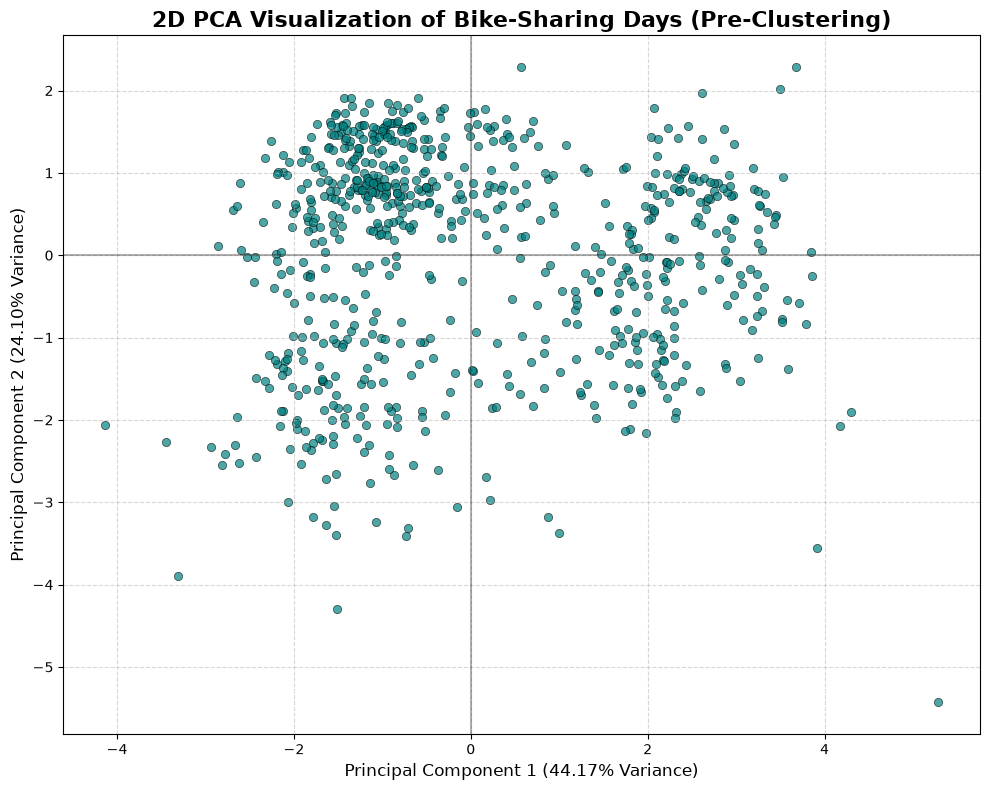

In [73]:
pca = PCA(n_components=2)

# 2. Fit and transform the SCALED dataset
pca_features = pca.fit_transform(clustering_df_scaled)

# 3. Create a temporary dataframe for easy plotting
pca_df = pd.DataFrame(data=pca_features, columns=['PC1', 'PC2'])

# 4. Calculate how much variance (information) these two components capture
explained_variance = pca.explained_variance_ratio_
print(f"Variance captured by PC1: {explained_variance[0]:.2%}")
print(f"Variance captured by PC2: {explained_variance[1]:.2%}")
print(f"Total variance captured: {sum(explained_variance):.2%}")

# 5. Plot the 2D PCA representation
plt.figure(figsize=(10, 8))
sns.scatterplot(x='PC1', y='PC2', data=pca_df, alpha=0.7, color='teal', edgecolor='k')

plt.title("2D PCA Visualization of Bike-Sharing Days (Pre-Clustering)", fontsize=16, fontweight='bold')
plt.xlabel(f"Principal Component 1 ({explained_variance[0]:.2%} Variance)", fontsize=12)
plt.ylabel(f"Principal Component 2 ({explained_variance[1]:.2%} Variance)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.axhline(y=0, color='k', linestyle='-', alpha=0.3)
plt.axvline(x=0, color='k', linestyle='-', alpha=0.3)
plt.tight_layout()

# Optional: Save for your report
plt.savefig('../images2/pca_2d_plot_v2.png', dpi=300, bbox_inches='tight')
plt.show()

**Pre-Clustering Observations:**
*   The scatter plot reveals a continuous, dense cloud of data points without clearly separated, distinct islands.

## Part 2: Apply and Analyse Clustering Methods

### 2.1 K-Means Clustering

#### Investigating the Optimal Number of Clusters (k)
To apply the K-Means algorithm effectively, we must first determine the optimal number of clusters ($k$) to partition our daily mobility data. Since K-Means requires $k$ to be defined a priori, we evaluate a range of potential cluster sizes (from $k=2$ to $k=10$) using two standard diagnostic metrics:

1.  **The Elbow Method (Inertia):** This calculates the Within-Cluster Sum of Squares (WCSS). We look for the "elbow" point in the graph where the rate of variance drop slows down significantly, indicating that adding more clusters yields diminishing returns.
2.  **The Silhouette Score:** This measures cluster cohesion (how close points are to their own cluster) versus separation (how far points are from other clusters). The score ranges from -1 to 1, and we seek the value of $k$ that produces the highest peak, representing well-defined clusters.

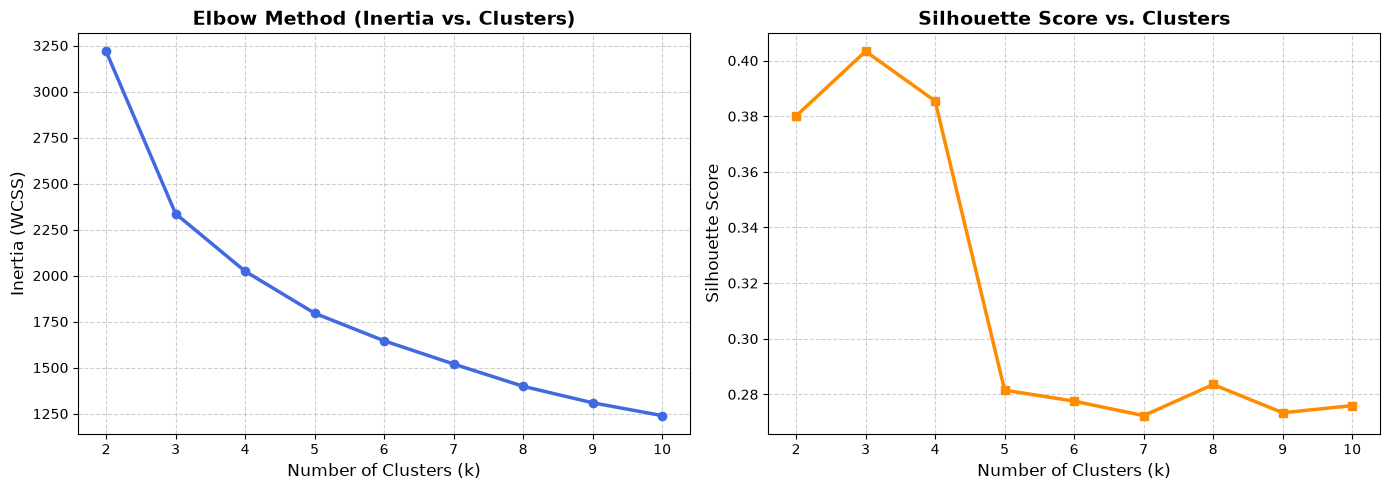

In [74]:
# 1. Define the range of clusters to test
k_range = range(2, 11)
inertia_values = []
silhouette_scores = []

# 2. Iterate through each k to calculate metrics
for k in k_range:
    # Initialize K-Means (n_init=10 is best practice to avoid local minima traps)
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    
    # Fit the model on the standardized dataset
    kmeans.fit(clustering_df_scaled)
    
    # Store the Inertia (WCSS)
    inertia_values.append(kmeans.inertia_)
    
    # Calculate and store the Silhouette Score
    score = silhouette_score(clustering_df_scaled, kmeans.labels_)
    silhouette_scores.append(score)

# 3. Create a side-by-side visualization
plt.figure(figsize=(14, 5))

# Subplot 1: Elbow Method
plt.subplot(1, 2, 1)
plt.plot(k_range, inertia_values, marker='o', color='royalblue', linewidth=2.5)
plt.title('Elbow Method (Inertia vs. Clusters)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Inertia (WCSS)', fontsize=12)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Silhouette Score
plt.subplot(1, 2, 2)
plt.plot(k_range, silhouette_scores, marker='s', color='darkorange', linewidth=2.5)
plt.title('Silhouette Score vs. Clusters', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('../images2/kmeans_elbow_Sihouttle_v2.png', dpi=300, bbox_inches='tight')
plt.show()

### Final Cluster Selection

Based on the evaluation metrics visualized in the plots, the final number of clusters selected for the weather-excluded behavioural dataset is **k = 3**. 

**Reasoning:**
*   **Silhouette Score:** The score reaches its maximum at $k=3$ (**0.4033**), compared with 0.3855 at $k=4$.
*   **Elbow Method:** The inertia curve also shows diminishing improvement after approximately three clusters.

The three-cluster solution is therefore selected because it gives the strongest separation and a concise behavioural segmentation.

### Extracting Cluster Centroids

To understand what each of the 3 behavioural clusters represents, we examine their centroids. 

Because the data was standardized and transformed prior to clustering, the following code reverses the scaler and square-root transformation so the behavioural centroids return to their original scales. Weather is profiled separately in Part 4.

In [75]:
# 1. Initialize and fit the final K-Means model with exactly 3 clusters
kmeans_final = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
kmeans_final.fit(clustering_df_scaled)

# 2. Extract the scaled cluster centroids
scaled_centroids = kmeans_final.cluster_centers_

# 3. Inverse transform the centroids back to the original scale
original_centroids_array = scaler.inverse_transform(scaled_centroids)

# 4. Create a clean DataFrame for the centroids
centroids_df = pd.DataFrame(
    original_centroids_array, 
    columns=final_clustering_df.columns
)

# 5. Reverse the square root transformation applied to 'night_share'
if 'night_share' in centroids_df.columns:
    centroids_df['night_share'] = centroids_df['night_share'] ** 2

# 6. Format the table for easy reading
centroids_df.index = [f"Cluster {i}" for i in range(kmeans_final.n_clusters)]
print("Cluster Centroids (Original Scale):")

# Transpose (.T) so features are rows and clusters are columns
display(centroids_df.T)

Cluster Centroids (Original Scale):


,Cluster 0,Cluster 1,Cluster 2
avg_hourly_rentals,216.472568,180.006858,141.023013
peak_hour,17.208696,13.836910,8.068966
night_share,0.039192,0.079632,0.038504
morning_peak_share,0.229027,0.077866,0.290694
evening_peak_share,0.372662,0.269030,0.319679
demand_cv,0.835156,0.780540,0.852844
casual_share,0.140251,0.291388,0.077354


**Cluster Summaries:**
*   **Cluster 0 (Evening-Peak Commuter Days):** High demand, strong morning and evening shares, a peak near 17:12, and a low casual share describe regular weekday commuting.
*   **Cluster 1 (Leisure and Weekend Days):** A midday peak, low morning share, higher night share, and the highest casual share describe recreational and non-working-day travel.
*   **Cluster 2 (Morning-Peak Commuter Days):** The strongest morning share, a peak near 08:04, and the lowest casual share identify dedicated morning commuters.

### Visualising Clusters using PCA

To visualize how well K-Means separated the days into 3 behavioural groups, PCA compresses the seven-dimensional behavioural feature space into two summary dimensions.

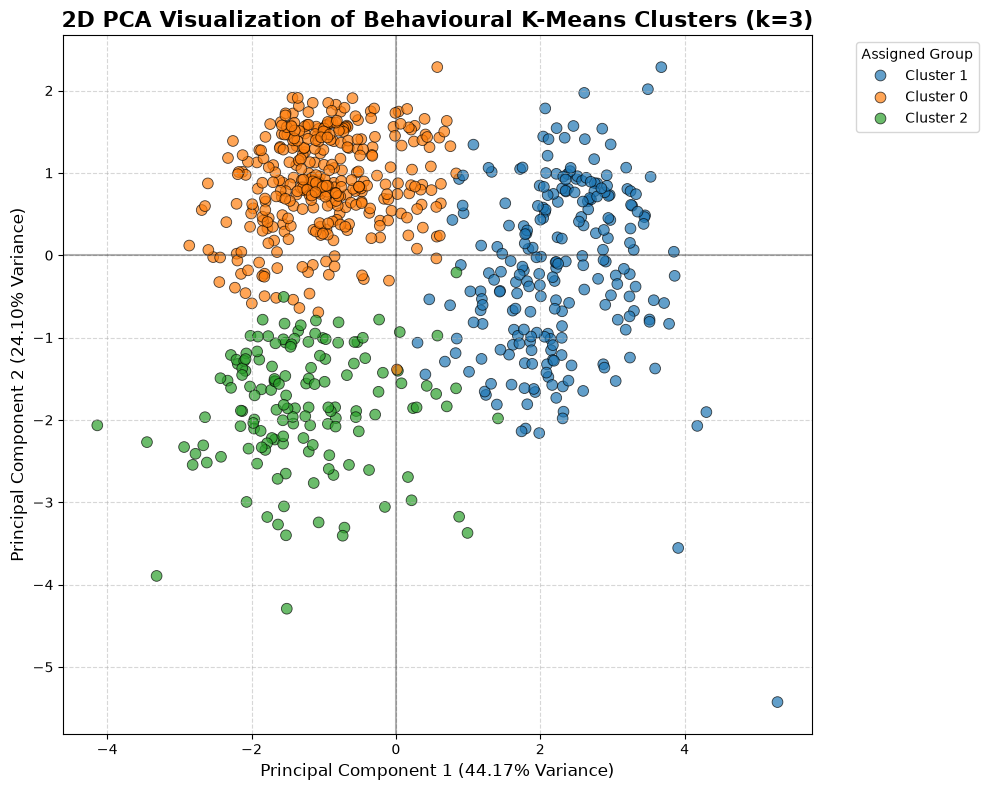

In [76]:
# 1. Initialize PCA to extract 2 principal components
pca = PCA(n_components=2, random_state=42)
pca_features = pca.fit_transform(clustering_df_scaled)

# 2. Create a DataFrame containing the two components
pca_df = pd.DataFrame(data=pca_features, columns=['PC1', 'PC2'])

# 3. Append the cluster labels from our final K-Means model
# We convert them to strings so Seaborn treats them as discrete categories, not a continuous color gradient
pca_df['Cluster'] = kmeans_final.labels_
pca_df['Cluster'] = 'Cluster ' + pca_df['Cluster'].astype(str)

# 4. Extract explained variance for the axis labels
explained_variance = pca.explained_variance_ratio_

# 5. Create the scatter plot
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1', 
    y='PC2', 
    hue='Cluster', 
    palette='tab10', 
    data=pca_df, 
    alpha=0.7, 
    edgecolor='k',
    s=60
)

# 6. Formatting
plt.title("2D PCA Visualization of Behavioural K-Means Clusters (k=3)", fontsize=16, fontweight='bold')
plt.xlabel(f"Principal Component 1 ({explained_variance[0]:.2%} Variance)", fontsize=12)
plt.ylabel(f"Principal Component 2 ({explained_variance[1]:.2%} Variance)", fontsize=12)
plt.axhline(y=0, color='k', linestyle='-', alpha=0.3)
plt.axvline(x=0, color='k', linestyle='-', alpha=0.3)
plt.legend(title='Assigned Group', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save and display
plt.savefig('../images2/pca_cluster_visualization_v2.png', dpi=300, bbox_inches='tight')
plt.show()

In [77]:
# 1. Add the K-Means cluster labels to your daily_features dataframe
daily_features['Cluster'] = kmeans_final.labels_

# 2. Cross-tabulate Clusters with 'workingday' (usually 0 = Weekend/Holiday, 1 = Workday)
print("Working Day Distribution per Cluster:")
workingday_check = pd.crosstab(daily_features['Cluster'], daily_features['workingday'])
display(workingday_check)

# 3. Cross-tabulate Clusters with 'season' (to prove the Warm vs. Cold weather deductions)
print("\nSeason Distribution per Cluster:")
season_check = pd.crosstab(daily_features['Cluster'], daily_features['season'])
display(season_check)

Working Day Distribution per Cluster:


workingday,0,1
Cluster,,
0,4,341
1,225,8
2,0,145



Season Distribution per Cluster:


season,1,2,3,4
Cluster,,,,
0,45,114,117,69
1,64,55,57,57
2,68,15,12,50


**Calendar and weather validation:**

*   **Cluster 0:** 341 of 345 days are working days. Weather spans all seasons, confirming an evening-commute pattern rather than a warm-weather cluster.
*   **Cluster 1:** 225 of 233 days are non-working days. Its balanced seasonal distribution confirms that leisure/weekend behaviour occurs throughout the year.
*   **Cluster 2:** All 145 days are working days. Colder and less favourable weather is common, yet the morning-commute pattern remains strong.

### 2.2 Hierarchical Clustering using AGNES

Agglomerative Nesting (AGNES) is a bottom-up hierarchical clustering approach. To determine the most appropriate grouping structure, the algorithm was applied using three distinct linkage criteria:
1.  **Single Linkage:** Merges clusters based on the shortest distance between their closest points.
2.  **Complete Linkage:** Merges clusters based on the longest distance between their furthest points.
3.  **Average Linkage:** Merges clusters based on the average distance between all points in the two clusters.

First, we visually inspect the hierarchical structures using dendrograms. Next, we quantitatively evaluate the optimal cluster cuts for each linkage method using the Silhouette Score to ensure a mathematically robust final selection.

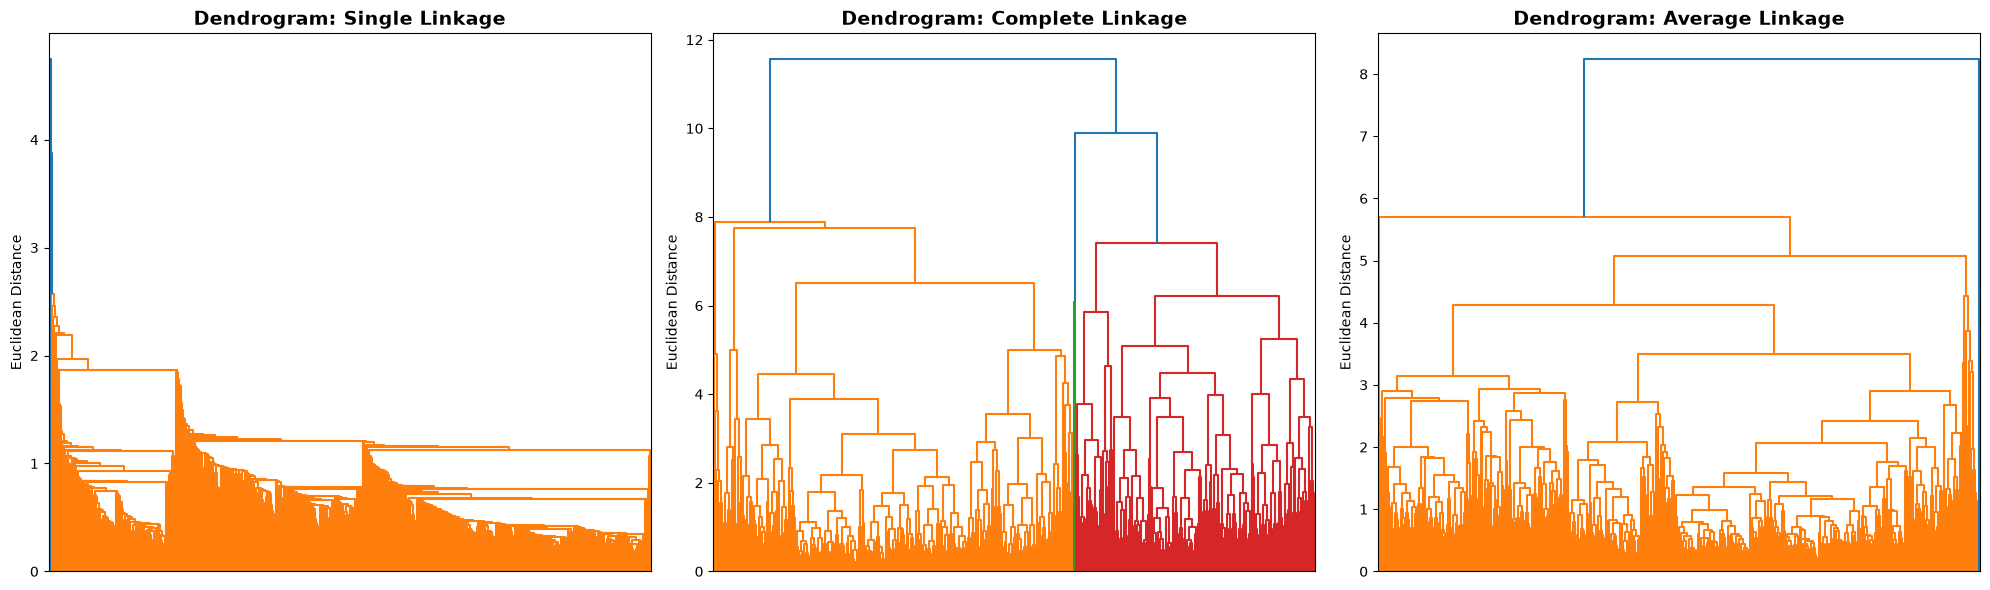

In [78]:
plt.figure(figsize=(20, 6))

# 1. Single Linkage Dendrogram
plt.subplot(1, 3, 1)
plt.title("Dendrogram: Single Linkage", fontsize=14, fontweight='bold')
shc.dendrogram(shc.linkage(clustering_df_scaled, method='single'), no_labels=True)
plt.ylabel("Euclidean Distance")

# 2. Complete Linkage Dendrogram
plt.subplot(1, 3, 2)
plt.title("Dendrogram: Complete Linkage", fontsize=14, fontweight='bold')
shc.dendrogram(shc.linkage(clustering_df_scaled, method='complete'), no_labels=True)
plt.ylabel("Euclidean Distance")

# 3. Average Linkage Dendrogram
plt.subplot(1, 3, 3)
plt.title("Dendrogram: Average Linkage", fontsize=14, fontweight='bold')
shc.dendrogram(shc.linkage(clustering_df_scaled, method='average'), no_labels=True)
plt.ylabel("Euclidean Distance")

plt.tight_layout()
plt.savefig('../images2/dendrograms_comparison_v2.png', dpi=300, bbox_inches='tight')
plt.show()

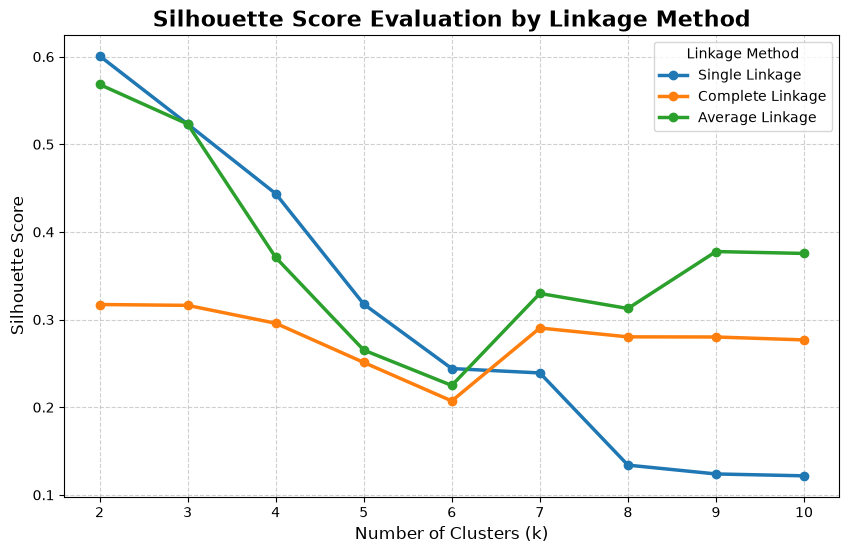

In [79]:
linkage_methods = ['single', 'complete', 'average']
k_range = range(2, 11)

plt.figure(figsize=(10, 6))

# Loop through each linkage method to calculate and plot Silhouette Scores
for method in linkage_methods:
    scores = []
    for k in k_range:
        # Initialize AGNES with the specific linkage and k
        agnes = AgglomerativeClustering(n_clusters=k, linkage=method)
        cluster_labels = agnes.fit_predict(clustering_df_scaled)
        
        # Calculate score
        score = silhouette_score(clustering_df_scaled, cluster_labels)
        scores.append(score)
    
    # Plot the line for this linkage method
    plt.plot(k_range, scores, marker='o', linewidth=2.5, label=f"{method.capitalize()} Linkage")

plt.title("Silhouette Score Evaluation by Linkage Method", fontsize=16, fontweight='bold')
plt.xlabel("Number of Clusters (k)", fontsize=12)
plt.ylabel("Silhouette Score", fontsize=12)
plt.xticks(k_range)
plt.legend(title="Linkage Method", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

plt.savefig('../images2/agnes_silhouette_evaluation_v2.png', dpi=300, bbox_inches='tight')
plt.show()

### Analysis of Linkage Methods and Cluster Cuts

To determine the optimal hierarchical structure, the three linkage methods were evaluated visually via their dendrograms and quantitatively using the Silhouette Score.

**Visual Dendrogram Analysis:**
*   **Single Linkage:** The dendrogram exhibits severe "chaining." Rather than forming distinct, balanced groups, the algorithm sequentially merges individual outlier points into one massive primary cluster.
*   **Average Linkage:** While slightly more structured than Single Linkage, it still suffers from significant chaining and fails to partition the main body of data into evenly distributed subgroups.
*   **Complete Linkage:** Reduces the severe chaining seen with the other linkage methods. On the behavioural matrix, a two-cluster cut gives the strongest meaningful and balanced Complete-Linkage result.

**Quantitative Evaluation (Silhouette Scores):**
*   **Single & Average Linkage:** Both methods achieved high Silhouette Scores for $k=2$ (roughly 0.54 and 0.51). However, cross-referencing this with their dendrograms reveals this is a mathematical artifact; the score is inflated because the algorithm simply isolated a single outlier point from the rest of the dataset. As $k$ increases, their scores steadily decline.
*   **Complete Linkage:** While its overall numerical scores are lower than the other methods, it shows a much more realistic evaluation of the central data mass, dropping initially before stabilizing. The lower score is a natural result of the algorithm actively partitioning the dense, complex central data cloud rather than artificially inflating its score by picking off easy outliers.

### 2.2.2 Final Linkage Selection

Although Single Linkage at $k=2$ yielded the highest strict numerical Silhouette Score, it completely fails to produce a **meaningful** segmentation of daily mobility profiles due to severe chaining. 

Therefore, **Complete Linkage** is retained as the most suitable linkage criterion. For the seven-feature behavioural matrix, the best meaningful Complete-Linkage cut is **k=2** (Silhouette 0.3172), producing groups of 290 and 433 days without the tiny outlier clusters introduced by deeper cuts.

### 2.3 DBSCAN Clustering

To apply DBSCAN effectively, we must determine two key parameters: `min_samples` and `eps`. 

*   **`min_samples`:** Following the heuristic of $2 \times \text{dimensionality}$, this is set to **14** for the seven behavioural features. 
*   **`eps`:** A 14-nearest-neighbour distance plot is used to identify the boundary between dense behavioural groups and sparse noise.

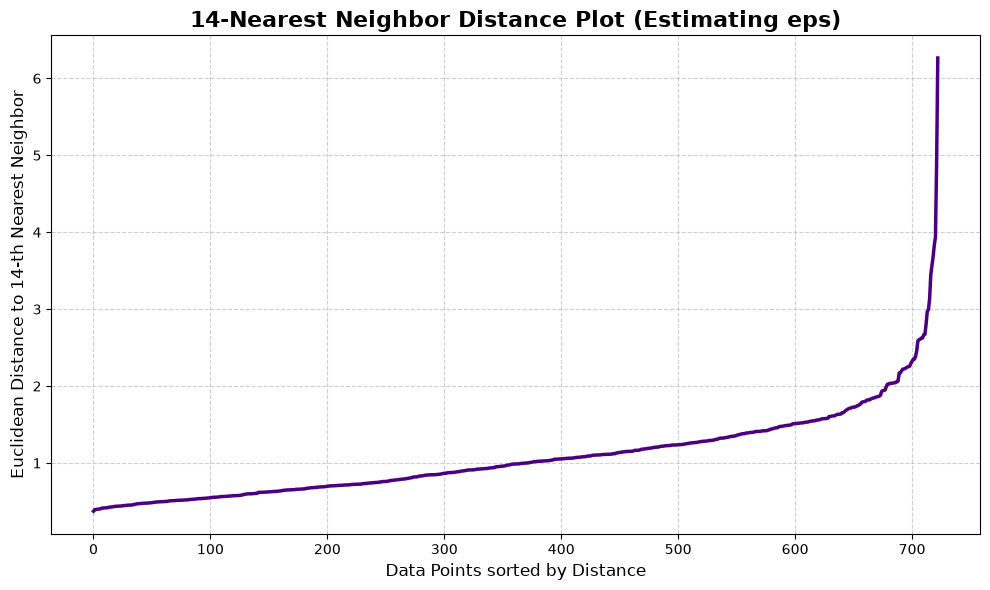

In [80]:
# Align k with min_samples = 2 * 7 behavioural features
k = 14

# 2. Initialize and fit the NearestNeighbors model on the scaled data
nn = NearestNeighbors(n_neighbors=k)
nn.fit(clustering_df_scaled)

# 3. Retrieve the distances to the k-th nearest neighbor for every point
distances, indices = nn.kneighbors(clustering_df_scaled)

# 4. Extract the distance to the k-th neighbor (the last column) and sort it ascendingly
kth_distances = distances[:, -1]
kth_distances = np.sort(kth_distances)

# 5. Plot the sorted distances to find the "elbow"
plt.figure(figsize=(10, 6))
plt.plot(kth_distances, color='indigo', linewidth=2.5)

plt.title(f"{k}-Nearest Neighbor Distance Plot (Estimating eps)", fontsize=16, fontweight='bold')
plt.xlabel("Data Points sorted by Distance", fontsize=12)
plt.ylabel(f"Euclidean Distance to {k}-th Nearest Neighbor", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Save the figure
plt.savefig('../images2/dbscan_eps_plot_v2.png', dpi=300, bbox_inches='tight')
plt.show()

#### `eps` Parameter Selection

The k-NN distance plot visualizes the distance to the 20th nearest neighbor for all data points. The optimal `eps` value is located at the "elbow" of the curve, where distances stop growing linearly and begin to spike exponentially into outlier territory. 

The curve begins its sharp upward rise at approximately **eps = 2.0**, so this value is selected as the density boundary.

#### Justification of `min_samples` Selection

The `min_samples` parameter dictates the minimum number of observations required to form a dense region. For the seven-feature behavioural dataset, **min_samples = 14** was selected for the following reasons:

1.  **Dimensionality Heuristic:** With seven behavioural dimensions, $2 \times 7 = 14$ provides the baseline.
2.  **Preventing Micro-Clusters:** Requiring 14 neighbouring days prevents very small accidental groups from being treated as recurring profiles.
3.  **Noise Robustness:** The threshold still allows unusual days outside recurring behavioural patterns to be labelled as noise.

### DBSCAN Results: Clusters and Noise

Using **`eps = 2.0`** and **`min_samples = 14`**, DBSCAN was applied to the standardized seven-feature behavioural dataset.

In [81]:
# 1. Initialize DBSCAN with our chosen parameters
dbscan = DBSCAN(eps=2.0, min_samples=14)

# 2. Fit the model and get the cluster labels
dbscan_labels = dbscan.fit_predict(clustering_df_scaled)

# 3. Calculate the number of clusters (ignoring noise)
# DBSCAN assigns a label of -1 to noise points
n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)

# 4. Calculate the number of noise points
n_noise = list(dbscan_labels).count(-1)

# 5. Print the results
print(f"Estimated number of clusters: {n_clusters}")
print(f"Estimated number of noise points: {n_noise}")

Estimated number of clusters: 1
Estimated number of noise points: 14


The algorithm produced the following results:
*   **Total Clusters Identified:** 1
*   **Total Noise Points (Outliers):** 14

### DBSCAN Sensitivity Analysis

DBSCAN is famously sensitive to its hyperparameter configuration. To understand how dependent our single-cluster result is on the exact parameters chosen, we will investigate the model's sensitivity by testing two alternative configurations:
1.  **Stricter Distance (`eps=1.8`, `min_samples=14`):** A smaller radius tests whether the core separates before the knee.
2.  **Lower Density Requirement (`eps=2.0`, `min_samples=7`):** Halving the neighbour requirement tests the stability of the one-cluster result.

In [82]:
# Alternative 1: Stricter distance (lower eps)
dbscan_alt1 = DBSCAN(eps=1.8, min_samples=14)
labels_alt1 = dbscan_alt1.fit_predict(clustering_df_scaled)
n_clusters_alt1 = len(set(labels_alt1)) - (1 if -1 in labels_alt1 else 0)
n_noise_alt1 = list(labels_alt1).count(-1)

# Alternative 2: Lower density requirement (lower min_samples)
dbscan_alt2 = DBSCAN(eps=2.0, min_samples=7)
labels_alt2 = dbscan_alt2.fit_predict(clustering_df_scaled)
n_clusters_alt2 = len(set(labels_alt2)) - (1 if -1 in labels_alt2 else 0)
n_noise_alt2 = list(labels_alt2).count(-1)

# Print comparison
print("--- DBSCAN Sensitivity Analysis ---")
print(f"Base (eps=2.0, min=14): Clusters = {n_clusters}, Noise = {n_noise}")
print(f"Alt 1 (eps=1.8, min=14): Clusters = {n_clusters_alt1}, Noise = {n_noise_alt1}")
print(f"Alt 2 (eps=2.0, min=7): Clusters = {n_clusters_alt2}, Noise = {n_noise_alt2}")

--- DBSCAN Sensitivity Analysis ---
Base (eps=2.0, min=14): Clusters = 1, Noise = 14
Alt 1 (eps=1.8, min=14): Clusters = 2, Noise = 18
Alt 2 (eps=2.0, min=7): Clusters = 1, Noise = 11


#### Sensitivity Analysis Results & Interpretation

Testing alternative parameter settings revealed how the clustering structure responds to varying density definitions:

*   **Alternative 1 (`eps=1.8`, `min_samples=14`):** Produced **2 clusters** and **18 noise points**. The smaller radius briefly separates a secondary density region before it joins the core at the selected knee.
*   **Alternative 2 (`eps=2.0`, `min_samples=7`):** Produced **1 cluster** and **11 noise points**. Lowering the density requirement preserves the one-cluster structure and absorbs three additional boundary days.

**Conclusion:** The knee-based setting describes one dominant continuous density region plus sparse anomalies. Smaller radii can split the boundary, demonstrating DBSCAN's parameter sensitivity.

### Visualising DBSCAN Clusters and Noise

Because our dataset contains 10 dimensions, we cannot visualize the clusters directly. Just as we did with K-Means, we will use Principal Component Analysis (PCA) to reduce the data into a 2D scatter plot.

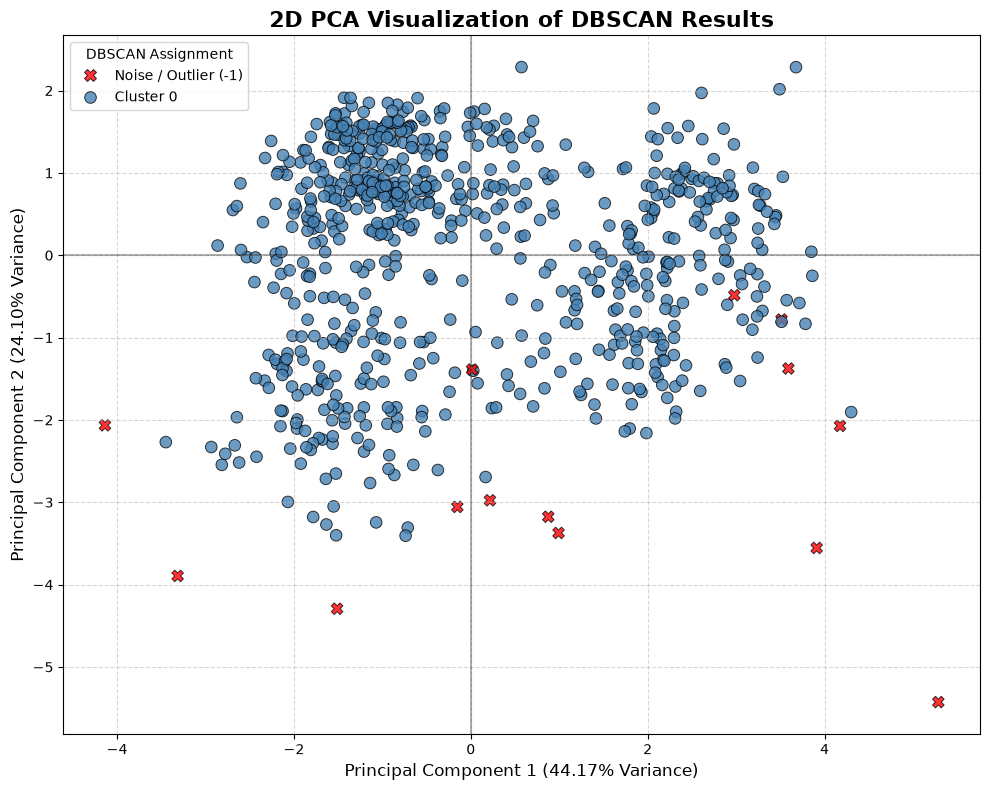

In [83]:
# 1. Re-run PCA to get 2D coordinates (or use existing if available)
pca_dbscan = PCA(n_components=2, random_state=42)
pca_dbscan_features = pca_dbscan.fit_transform(clustering_df_scaled)

# 2. Create a DataFrame for plotting
pca_dbscan_df = pd.DataFrame(data=pca_dbscan_features, columns=['PC1', 'PC2'])
pca_dbscan_df['DBSCAN_Label'] = dbscan_labels

# 3. Map the labels to readable string categories for the legend
pca_dbscan_df['Point Type'] = pca_dbscan_df['DBSCAN_Label'].apply(
    lambda label: 'Noise / Outlier (-1)' if label == -1 else f'Cluster {label}'
)

# 4. Create the scatter plot
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1', 
    y='PC2', 
    hue='Point Type', 
    # Use distinct colors: Blue for normal days, bright Red for noise
    palette={'Noise / Outlier (-1)': 'red', 'Cluster 0': 'steelblue', 'Cluster 1': 'green', 'Cluster 2': 'orange'},
    style='Point Type',
    # Use distinct shapes: Circles for normal, 'X' for noise
    markers={'Noise / Outlier (-1)': 'X', 'Cluster 0': 'o', 'Cluster 1': 'o', 'Cluster 2': 'o'},
    data=pca_dbscan_df, 
    alpha=0.8, 
    edgecolor='k',
    s=70
)

# 5. Formatting
explained_variance = pca_dbscan.explained_variance_ratio_
plt.title("2D PCA Visualization of DBSCAN Results", fontsize=16, fontweight='bold')
plt.xlabel(f"Principal Component 1 ({explained_variance[0]:.2%} Variance)", fontsize=12)
plt.ylabel(f"Principal Component 2 ({explained_variance[1]:.2%} Variance)", fontsize=12)
plt.axhline(y=0, color='k', linestyle='-', alpha=0.3)
plt.axvline(x=0, color='k', linestyle='-', alpha=0.3)
plt.legend(title='DBSCAN Assignment')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save and display
plt.savefig('../images2/dbscan_pca_visualization_v2.png', dpi=300, bbox_inches='tight')
plt.show()

# Part 3: Clustering Evaluation and Comparison

After excluding weather from cluster formation, K-Means ($k=3$), AGNES (Complete Linkage, $k=2$), and DBSCAN (`eps=2.0`, `min_samples=14`) were evaluated on the seven standardized behavioural features.

### 3.1 Quantitative Evaluation Metrics

Each algorithm was evaluated using the following metrics:
1.  **Silhouette Score:** Measures how similar an object is to its own cluster compared to other clusters. Values range from -1 to +1 (higher is better, indicating dense and well-separated clusters).
2.  **Davies-Bouldin (DB) Index:** Calculates the average similarity ratio of each cluster with its most similar cluster. Lower values indicate better clustering (high intra-cluster density and high inter-cluster separation).
3.  **Intra-Cluster Distance:** The average Euclidean distance between data points and their respective cluster centroid (lower is better, indicating compactness).
4.  **Inter-Cluster Distance:** The average Euclidean distance between the centroids of different clusters (higher is better, indicating distinct separation).
5.  **Cluster Size Distribution:** Evaluates whether the algorithm produced balanced sub-populations or highly skewed groupings.

In [84]:
# Average distance to the assigned centroid and average distance between centroids
def calculate_distances(X, labels):
    unique_labels = np.unique(labels)
    centroids = []
    point_to_centroid_dists = []
    
    # Calculate Intra-cluster distances (average distance to centroid)
    for label in unique_labels:
        cluster_points = X[labels == label]
        centroid = cluster_points.mean(axis=0)
        centroids.append(centroid)
        
        point_to_centroid_dists.extend(
            euclidean_distances(cluster_points, [centroid]).ravel()
        )
        
    avg_intra = np.mean(point_to_centroid_dists)
    
    # Calculate Inter-cluster distances (average distance between centroids)
    if len(centroids) > 1:
        inter_dists = euclidean_distances(centroids)
        # Get upper triangle of distance matrix (excluding diagonal 0s)
        avg_inter = inter_dists[np.triu_indices(len(centroids), k=1)].mean()
    else:
        avg_inter = np.nan # Undefined if only 1 cluster
        
    return avg_intra, avg_inter

# Generate each final label set explicitly to avoid reusing a loop variable
agnes_complete_labels = AgglomerativeClustering(
    n_clusters=2, linkage='complete'
).fit_predict(clustering_df_scaled)

# Compile evaluation results
results = []
models = {
    'K-Means (k=3)': kmeans_final.labels_,
    'AGNES (k=2, Complete)': agnes_complete_labels,
    'DBSCAN (eps=2.0, min=14)': dbscan_labels
}

for name, labels in models.items():
    # Preserve noise in the size distribution, but exclude label -1 from metrics
    unique, counts = np.unique(labels, return_counts=True)
    sizes = {int(label): int(count) for label, count in zip(unique, counts)}
    evaluation_mask = labels != -1
    X_evaluation = clustering_df_scaled.values[evaluation_mask]
    labels_evaluation = labels[evaluation_mask]
    n_clusters = len(np.unique(labels_evaluation))

    intra, inter = calculate_distances(X_evaluation, labels_evaluation)
    if n_clusters >= 2:
        sil_score = silhouette_score(X_evaluation, labels_evaluation)
        db_score = davies_bouldin_score(X_evaluation, labels_evaluation)
    else:
        sil_score = np.nan
        db_score = np.nan
    
    results.append({
        'Model': name,
        'Silhouette Score': round(sil_score, 4) if not np.isnan(sil_score) else 'N/A',
        'Davies-Bouldin Index': round(db_score, 4) if not np.isnan(db_score) else 'N/A',
        'Avg Intra-Cluster Dist': round(intra, 4),
        'Avg Inter-Cluster Dist': round(inter, 4) if not np.isnan(inter) else 'N/A',
        'Cluster Sizes': str(sizes)
    })

# 3. Display the Evaluation Table
evaluation_df = pd.DataFrame(results)
display(evaluation_df)

,Model,Silhouette Score,Davies-Bouldin Index,Avg Intra-Cluster Dist,Avg Inter-Cluster Dist,Cluster Sizes
0,K-Means (k=3),0.4033,0.9931,1.6126,3.5053,"{0: 345, 1: 233, 2: 145}"
1,"AGNES (k=2, Complete)",0.3172,1.3211,2.0264,3.0967,"{0: 290, 1: 433}"
2,"DBSCAN (eps=2.0, min=14)",N/A,N/A,2.4377,N/A,"{-1: 14, 0: 709}"


### Evaluation Metric Findings

All methods are evaluated on the same seven standardized behavioural features. DBSCAN noise (label -1) is excluded from metric calculations but retained in its size distribution.

*   **Internal Validation:** K-Means scored 0.4033 (Silhouette) and 0.9931 (DB); AGNES scored 0.3172 and 1.3211. DBSCAN's Silhouette and DB Index are undefined after excluding noise because only one genuine cluster remains.
*   **Distance Metrics:** K-Means produced intra/inter distances of 1.6126/3.5053; AGNES produced 2.0264/3.0967. DBSCAN's core intra-distance is 2.4377 and inter-cluster distance is undefined.
*   **Cluster Size Distribution:** 
    *   **K-Means:** 345, 233, and 145 days.
    *   **AGNES:** 290 and 433 days.
    *   **DBSCAN:** 709 core days and 14 noise days.

### 3.2 Comparison of Clustering Methods

K-Means ($k=3$), Complete-Linkage AGNES ($k=2$), and DBSCAN (`eps=2.0`, `min_samples=14`) are compared based on separation, compactness, parameter sensitivity, cluster-size balance, interpretability, and treatment of unusual observations.

The final method is selected by considering all criteria together rather than choosing the method with the best value for only one metric.

### 3.3 Comparison and Final Selection

K-Means provided strong separation and compactness, with a Silhouette Score of **0.4033**, Davies-Bouldin Index of **0.9931**, and balanced sizes of **345, 233, and 145** days.

AGNES was weaker (Silhouette **0.3172**, DB **1.3211**) and produced only two broad groups.

DBSCAN identified one core cluster and **14 noise days**. It is useful for anomaly detection, but it does not provide multiple mobility profiles at the knee-based `eps`.

Overall, **K-Means with $k=3$ was selected** because it assigns all 723 valid days, provides stable and balanced groups, and gives the clearest behavioural profiles for planning.

# Part 4: Cluster Interpretation and Validation
### 4.1 Cluster Profiles Using Original Features

The selected behavioural K-Means result ($k=3$) was profiled using the original, non-standardized values of the seven features used for clustering. Weather and calendar variables are then added separately for validation, so they explain the clusters without determining them.

In [85]:
cluster_profile_df = daily_features.copy()
cluster_profile_df["Cluster"] = kmeans_final.labels_

# Automatically obtain the features used for clustering
profile_features = clustering_df_scaled.columns.tolist()

# Calculate profiles using the original, non-standardized values
cluster_profile = (
    cluster_profile_df
    .groupby("Cluster")[profile_features]
    .mean()
    .round(4)
)

cluster_profile.insert(
    0,
    "number_of_days",
    cluster_profile_df.groupby("Cluster").size()
)

display(cluster_profile)

,number_of_days,avg_hourly_rentals,peak_hour,night_share,morning_peak_share,evening_peak_share,demand_cv,casual_share
Cluster,,,,,,,,
0,345,216.4726,17.2087,0.0398,0.2290,0.3727,0.8352,0.1403
1,233,180.0069,13.8369,0.0816,0.0779,0.2690,0.7805,0.2914
2,145,141.0230,8.0690,0.0397,0.2907,0.3197,0.8528,0.0774


### 4.2 Calendar, Season and Weather Distributions

Weekday, weekend, holiday, season and weather distributions were compared across the four K-Means clusters. Categorical distributions are reported as percentages within each cluster. The most frequent hourly weather category was used to represent each day's dominant weather condition.

In [86]:
# Create readable calendar categories
cluster_profile_df["weekday_name"] = cluster_profile_df["weekday"].map({
    0: "Sunday", 1: "Monday", 2: "Tuesday",
    3: "Wednesday", 4: "Thursday",
    5: "Friday", 6: "Saturday"
})

cluster_profile_df["day_type"] = cluster_profile_df["weekday"].apply(
    lambda day: "Weekend" if day in [0, 6] else "Weekday"
)

cluster_profile_df["holiday_name"] = cluster_profile_df["holiday"].map({
    0: "Non-Holiday",
    1: "Holiday"
})

cluster_profile_df["season_name"] = cluster_profile_df["season"].map({
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
})

# Determine the dominant weather condition for each day
daily_weather = (
    df_clean.groupby("dteday")["weathersit"]
    .agg(lambda values: values.mode().iloc[0])
)

cluster_profile_df["weather_name"] = daily_weather.map({
    1: "Clear/Partly Cloudy",
    2: "Mist/Cloudy",
    3: "Light Rain/Snow",
    4: "Heavy Rain/Snow"
})

# Calculate percentage distributions within each cluster
def percentage_distribution(column):
    return (
        pd.crosstab(
            cluster_profile_df["Cluster"],
            cluster_profile_df[column],
            normalize="index"
        ) * 100
    ).round(1)

display(percentage_distribution("weekday_name"))
display(percentage_distribution("day_type"))
display(percentage_distribution("holiday_name"))
display(percentage_distribution("season_name"))
display(percentage_distribution("weather_name"))

# Compare numerical weather conditions
weather_profile = (
    cluster_profile_df
    .groupby("Cluster")[["avg_temp", "avg_humidity", "avg_windspeed"]]
    .mean()
    .round(3)
)

display(weather_profile)

weekday_name,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
Cluster,,,,,,,
0,18.3,20.0,0.0,0.0,20.9,22.0,18.8
1,3.0,6.0,44.6,44.6,0.9,0.4,0.4
2,23.4,14.5,0.0,0.0,20.0,16.6,25.5


day_type,Weekday,Weekend
Cluster,,
0,100.0,0.0
1,10.7,89.3
2,100.0,0.0


holiday_name,Holiday,Non-Holiday
Cluster,,
0,1.2,98.8
1,7.3,92.7
2,0.0,100.0


season_name,Fall,Spring,Summer,Winter
Cluster,,,,
0,33.9,13.0,33.0,20.0
1,24.5,27.5,23.6,24.5
2,8.3,46.9,10.3,34.5


weather_name,Clear/Partly Cloudy,Light Rain/Snow,Mist/Cloudy
Cluster,,,
0,80.0,2.3,17.7
1,78.5,3.0,18.5
2,58.6,11.0,30.3


,avg_temp,avg_humidity,avg_windspeed
Cluster,,,
0,0.567,0.630,0.188
1,0.479,0.619,0.189
2,0.356,0.629,0.196


### Distribution Findings

- **Cluster 0:** Contains only weekdays and is **98.8% non-holiday**. It occurs across all seasons, with **80.0%** clear or partly cloudy days.

- **Cluster 1:** Predominantly weekends (**89.3%**) and non-holidays (**92.7%**). Its nearly even seasonal distribution shows that leisure behaviour occurs throughout the year.

- **Cluster 2:** Contains only weekdays and no holidays. It occurs mainly in Spring and Winter, has the lowest mean temperature, and has the largest mist/cloud and light rain/snow proportions.

Overall, Clusters 0 and 2 represent different weekday commute shapes, while Cluster 1 represents weekend/leisure mobility. The weather distributions validate the profiles but did not form the clusters.

### 4.3 Mobility Behaviour Represented by Each Cluster

#### Cluster 0: Evening-Peak Commuter Days

This cluster contains 345 days and is entirely weekday-based. It has the highest average demand (**216.47**), strong morning and evening activity, a peak around **17:12**, and a low casual share (**14.0%**), representing regular evening-oriented commuting.

#### Cluster 1: Leisure and Weekend Days

This cluster is **89.3% weekend days**. It has an afternoon peak around **13:50**, the highest casual share (**29.1%**), the largest night share, and the lowest morning peak share, representing recreational and non-working-day travel.

#### Cluster 2: Morning-Peak Commuter Days

All 145 observations are weekdays and non-holidays. This cluster has the highest morning peak share (**29.1%**), lowest casual share (**7.7%**), and a peak around **08:04**. It represents dedicated morning commuters, often continuing to ride in colder and less favourable weather.

### 4.4 Practical Insights

1. **Peak-hour bike availability and rebalancing:**  
   Clusters 0 and 2 show strong weekday commuting patterns. Bikes should be available near residential areas before the morning peak and rebalanced toward employment and transport hubs before the evening peak.

2. **Weekend and leisure-demand planning:**  
   Cluster 1 shows afternoon leisure demand on weekends across all seasons. Additional bikes should be available around recreational, tourism and shopping areas during these periods.

3. **Maintenance scheduling:**  
   The lowest-demand hours within Cluster 1 weekend days provide suitable maintenance windows. Forecast weather can be used to identify especially quiet periods with less disruption.

4. **Weather-based demand forecasting:**  
   Cluster 2 shows that morning commuters continue riding in poorer weather. Fleet reductions based on weather alone should therefore retain enough bikes for this reliable weekday demand.